In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# sns.set(font_scale=1.4)

In [2]:
df_mrms = pd.read_parquet(f"bootstrapping/results_mrms.parquet").fillna(value=np.nan)
df_warn = pd.read_parquet(f"bootstrapping/results_warn.parquet").fillna(value=np.nan)

/glade/derecho/scratch/ggantos/tmp/ipykernel_20195/1497141235.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_mrms = pd.read_parquet(f"bootstrapping/results_mrms.parquet").fillna(value=np.nan)
/glade/derecho/scratch/ggantos/tmp/ipykernel_20195/1497141235.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_warn = pd.read_parquet(f"bootstrapping/results_warn.parquet").fillna(value=np.nan)


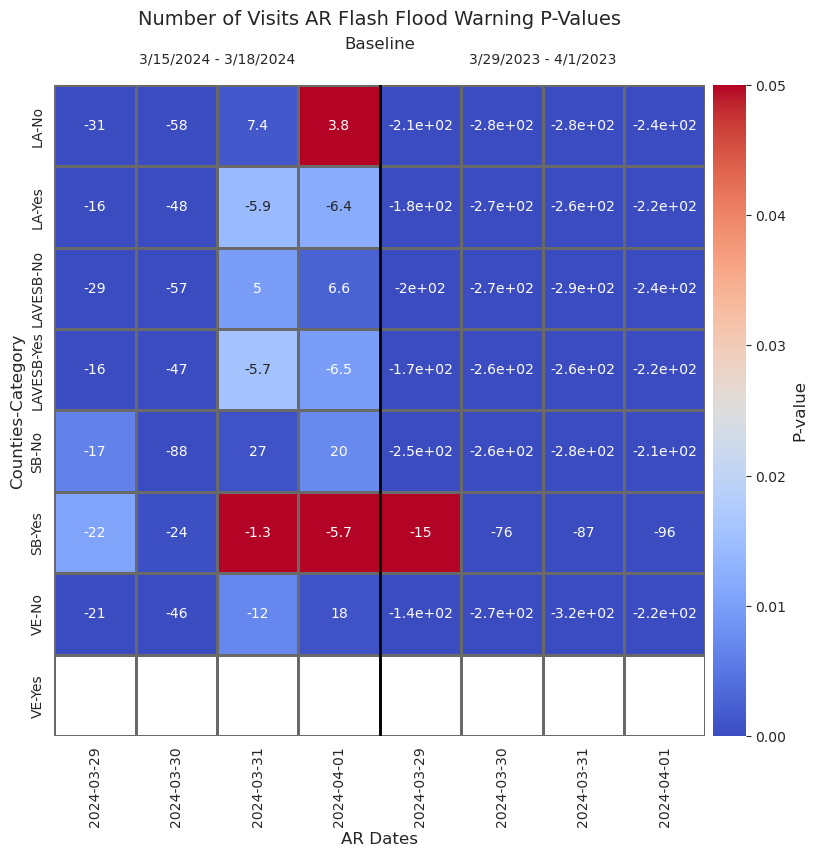

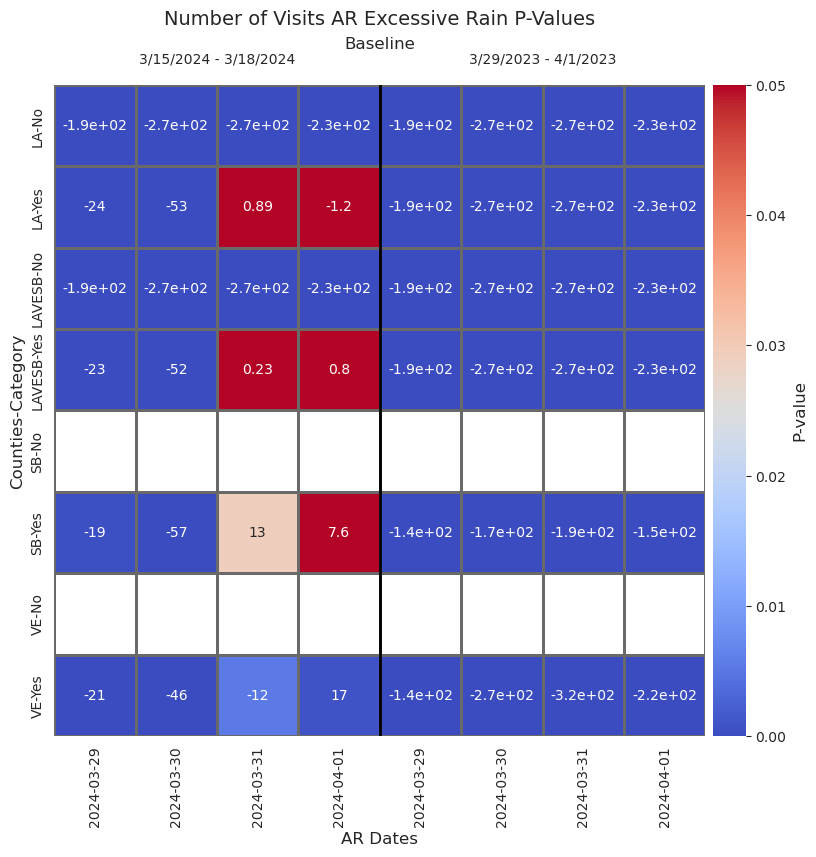

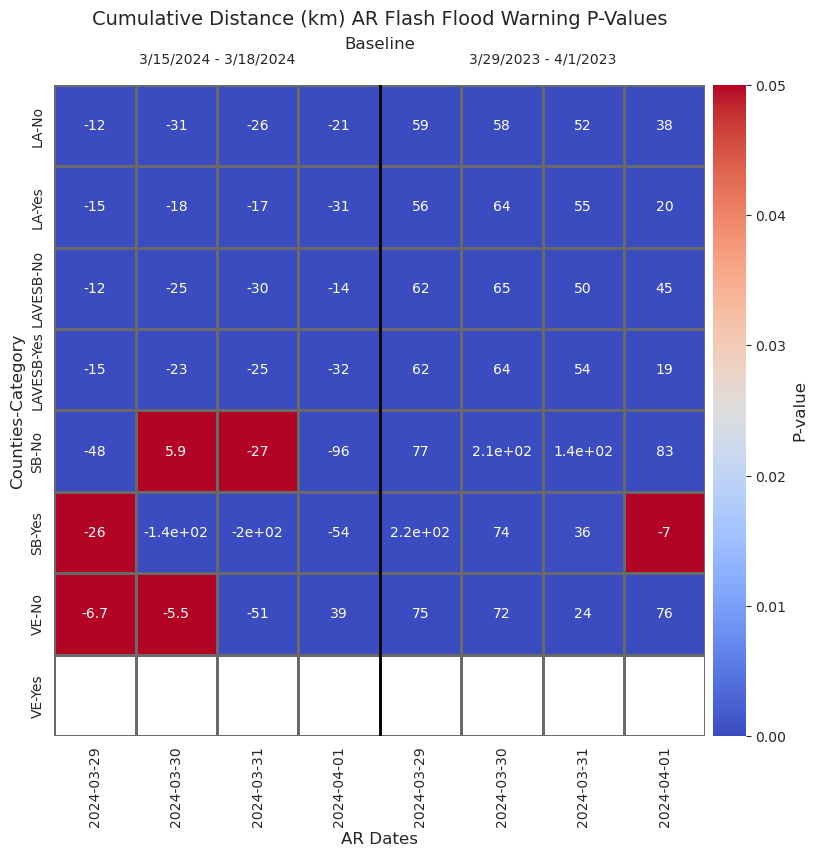

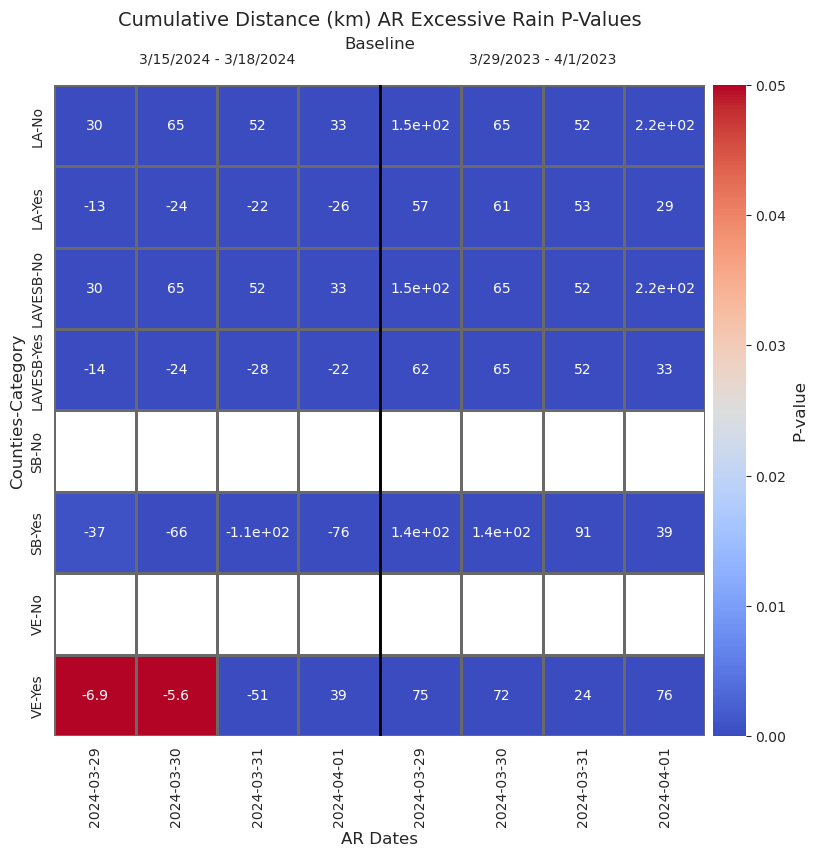

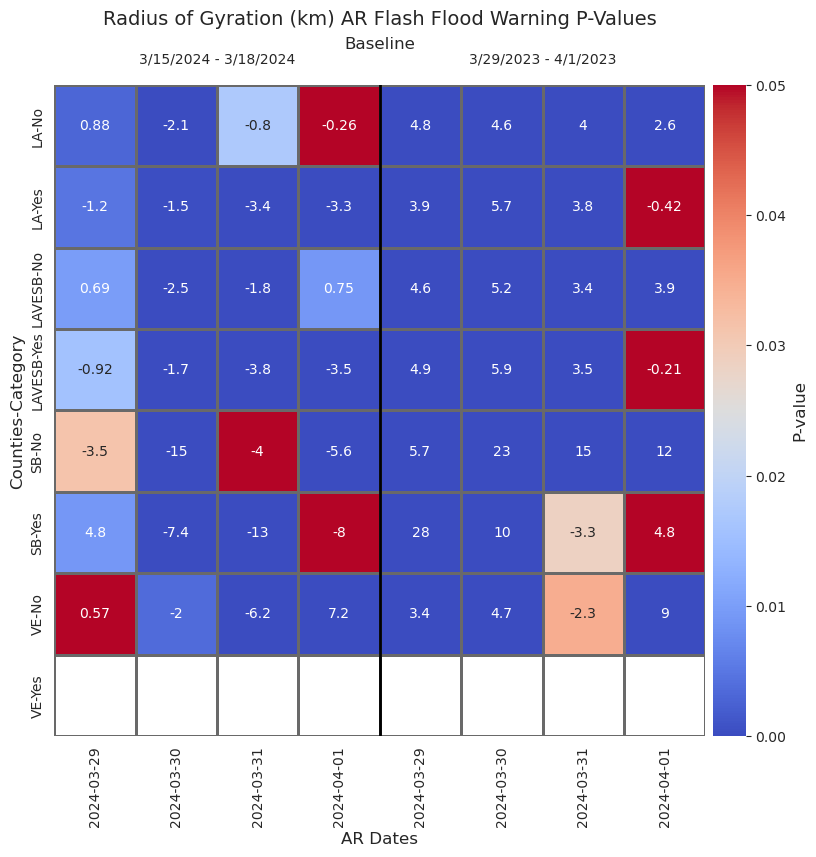

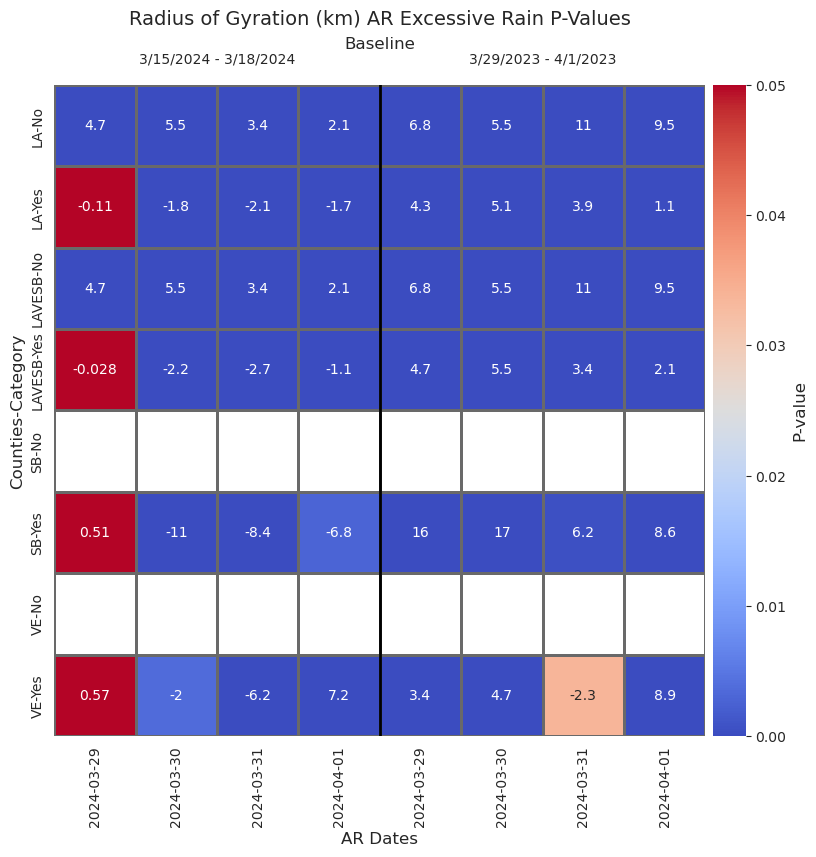

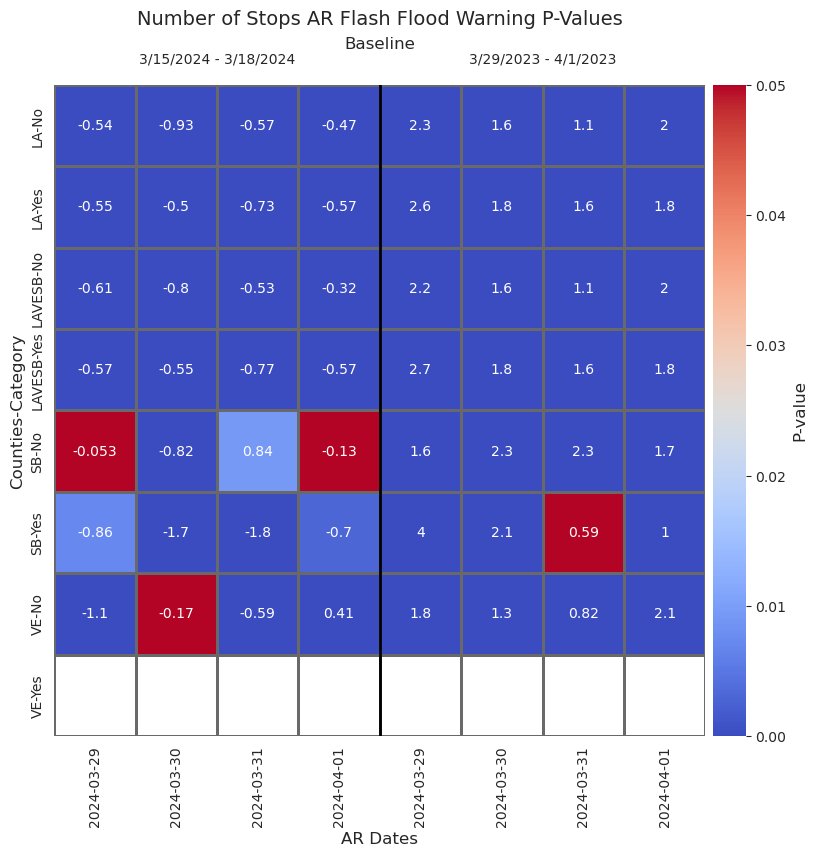

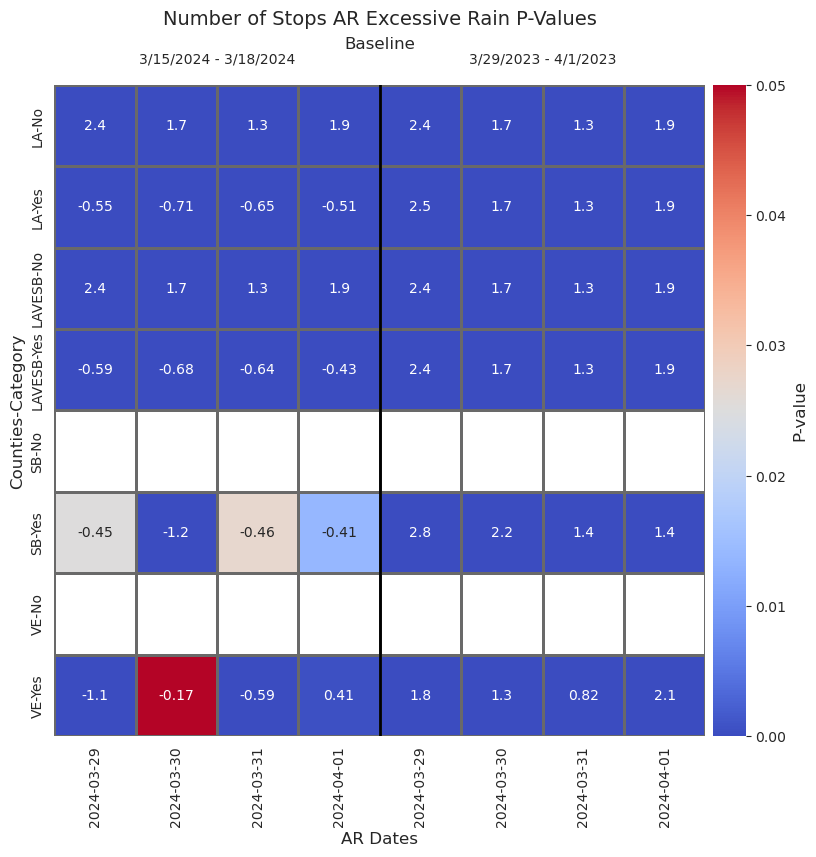

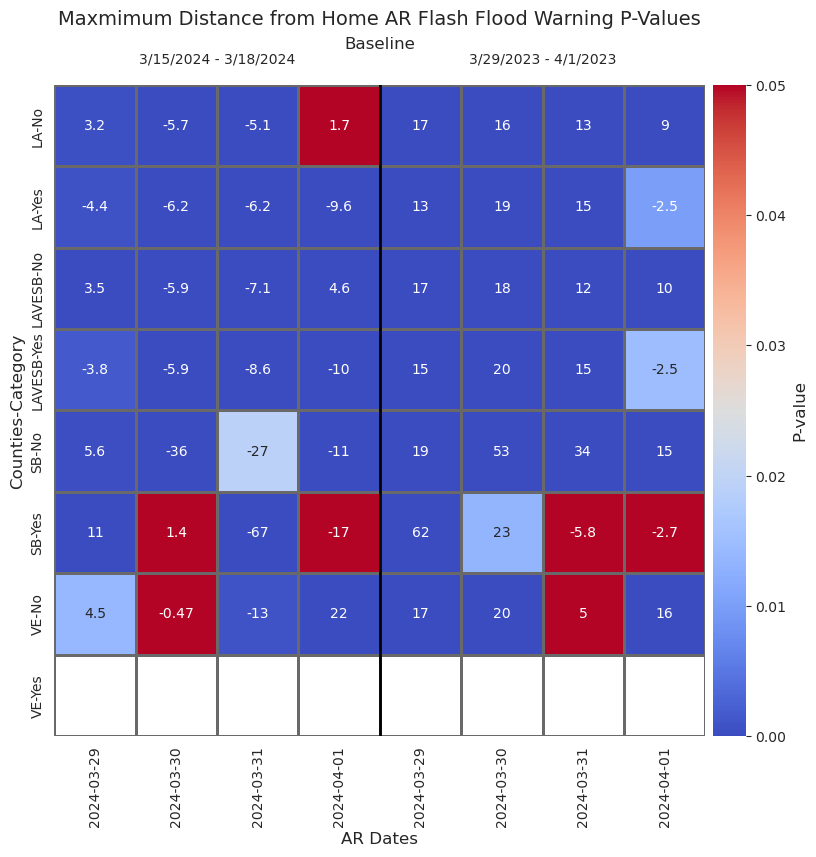

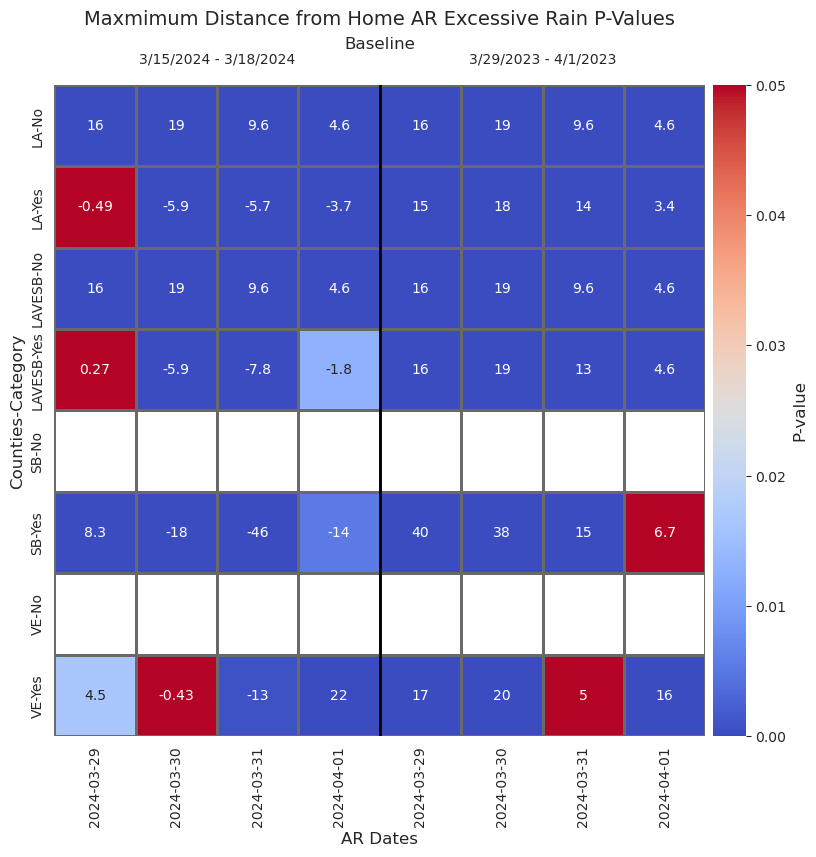

In [29]:
mobility_labels = [
    "Number of Visits",
    "Cumulative Distance (km)",
    "Radius of Gyration (km)",
    "Number of Stops",
    "Maxmimum Distance from Home",
]
mobility_metrics = [
    "number_of_visits",
    "distance_straight_line",
    "radius_of_gyration",
    "num_stops",
    "max_distance_from_home",
]
mrms_labels = ["AR Flash Flood Warning",
               "AR Excessive Rain"]
mrms_metrics = ["AR_ffw", "AR_er"]

for i,mobility_label in enumerate(mobility_labels):
    for j,mrms_label in enumerate(mrms_labels):
        df_plot = df_warn.loc[mobility_label, (mrms_label, slice(None), slice(None), slice(None), slice(None))].droplevel("Weather Metric", axis=1)
        df_plot_stack = df_plot.T.unstack("Dates").loc[slice(None), slice(None), slice(None)]

        sns.set_style(style='white')
        plt.figure(figsize=(10, 9))
        g1 = sns.heatmap(df_plot_stack.loc[slice(None), slice(None), "pvalue"],
                         annot=df_plot_stack.loc[slice(None), slice(None), "boot_mean"],
                         annot_kws={"size": 10},
                         fmt=".2g",
                         linewidths=.75,
                         linecolor='dimgrey',
                         cmap="coolwarm",
                         cbar_kws={'label': 'P-value', 'shrink': 0.94, 'aspect': 20, 'pad': 0.01},
                         vmin=0.0,
                         vmax=0.05,
                         square=True,
                        )
        g1.figure.axes[-1].yaxis.label.set_size(12)
        g1.set_xticklabels(df_plot_stack.columns.get_level_values("Dates"))
        g1.tick_params(axis='x', which='major', labelsize=10)
        g1.tick_params(axis='y', which='major', labelsize=10)
        plt.axvline(x=4, ymin=-1.0, ymax=9.0, linewidth=2, color='black')
        g1.text(2, -0.4, df_plot_stack.columns.get_level_values("Baseline").unique()[0], fontsize=10,
                horizontalalignment='center', verticalalignment='top')
        g1.text(6, -0.4, df_plot_stack.columns.get_level_values("Baseline").unique()[1], fontsize=10,
                horizontalalignment='center', verticalalignment='top')
        g1.text(4, -0.6, "Baseline", fontsize=12,
                horizontalalignment='center', verticalalignment='top')
        
        g1.set_xlabel("AR Dates", fontsize=12)
        g1.set_ylabel("Counties-Category", fontsize=12)
        plt.title(f"{mobility_label} {mrms_label} P-Values", y=1.08, fontsize=14)

        plt.savefig(f"bootstrapping/bootstrap_heatmap_{mobility_metrics[i]}_{mrms_metrics[j]}.png", dpi=300, bbox_inches="tight")
        plt.show()

In [ ]:
mobility_labels = [
    "Number of Visits",
    "Cumulative Distance (km)",
    "Radius of Gyration (km)",
    "Number of Stops",
    "Maxmimum Distance from Home",
]
mobility_metrics = [
    "number_of_visits",
    "distance_straight_line",
    "radius_of_gyration",
    "num_stops",
    "max_distance_from_home",
]
mrms_labels = ["Precipitation Sum",
               "Flood Max"]
mrms_metrics = ["precip_sum", "flood_max"]

for i,mobility_label in enumerate(mobility_labels):
    for j,mrms_label in enumerate(mrms_labels):
        for perc in df_mrms.index.get_level_values("Percentile").unique():
            df_plot = df_mrms.loc[(perc, mobility_label), (mrms_label, slice(None), slice(None), slice(None), slice(None))].droplevel("Weather Metric", axis=1)
            df_plot_stack = df_plot.T.unstack("Dates").loc[slice(None), slice(None), slice(None)]
    
            sns.set_style(style='white')
            plt.figure(figsize=(10, 10))
            g1 = sns.heatmap(df_plot_stack.loc[slice(None), slice(None), "pvalue"],
                             annot=df_plot_stack.loc[slice(None), slice(None), "boot_mean"],
                             annot_kws={"size": 10},
                             fmt=".2g",
                             linewidths=.75,
                             linecolor='dimgrey',
                             cmap="coolwarm",
                             cbar_kws={'label': 'P-value', 'shrink': 1.0, 'aspect': 10, 'pad': 0.01},
                             vmin=0.0,
                             vmax=0.05,
                             square=True,
                            )
            g1.figure.axes[-1].yaxis.label.set_size(12)
            g1.set_xticklabels(df_plot_stack.columns.get_level_values("Dates"))
            g1.tick_params(axis='x', which='major', labelsize=10)
            g1.tick_params(axis='y', which='major', labelsize=10)
            plt.axvline(x=4, ymin=-1.0, ymax=9.0, linewidth=2, color='black')
            g1.text(2, -0.4, df_plot_stack.columns.get_level_values("Baseline").unique()[0], fontsize=10,
                    horizontalalignment='center', verticalalignment='top')
            g1.text(6, -0.4, df_plot_stack.columns.get_level_values("Baseline").unique()[1], fontsize=10,
                    horizontalalignment='center', verticalalignment='top')
            g1.text(4, -0.9, "Baseline", fontsize=12,
                    horizontalalignment='center', verticalalignment='top')
            
            g1.set_xlabel("AR Dates", fontsize=12)
            g1.set_ylabel("Counties-Category", fontsize=12)
            plt.title(f"{mobility_label} {mrms_label} P-Values", y=1.025, fontsize=14)
            plt.savefig(f"bootstrapping/bootstrap_heatmap_{mobility_metrics[i]}_{mrms_metrics[j]}_{perc}.png", dpi=300, bbox_inches="tight")
            plt.show()

In [54]:
df_mrms

Weather Metric                                               Precipitation Sum  \
Counties                                                                    LA   
Dates                                                               2024-03-29   
Category                                                                  High   
Statistic                                                               pvalue   
Percentile Mobility Metric             Baseline                                  
1%         Number of Visits            3/15/2024 - 3/18/2024          0.017102   
                                       3/29/2023 - 4/1/2023           0.000000   
           Cumulative Distance (km)    3/15/2024 - 3/18/2024          0.000000   
                                       3/29/2023 - 4/1/2023           0.001000   
           Radius of Gyration (km)     3/15/2024 - 3/18/2024          0.401940   
                                       3/29/2023 - 4/1/2023           0.000000   
           Number of Stops             3/15/2024 - 3/18/2024          0.000000   
                                       3/29/2023 - 4/1/2023           0.000000   
           Maxmimum Distance from Home 3/15/2024 - 3/18/2024          0.000000   
                                       3/29/2023 - 4/1/2023           0.000000   
2.5%       Number of Visits            3/15/2024 - 3/18/2024          0.086809   
                                       3/29/2023 - 4/1/2023           0.000500   
           Cumulative Distance (km)    3/15/2024 - 3/18/2024          0.000800   
                                       3/29/2023 - 4/1/2023           0.000000   
           Radius of Gyration (km)     3/15/2024 - 3/18/2024          0.336734   
                                       3/29/2023 - 4/1/2023           0.301730   
           Number of Stops             3/15/2024 - 3/18/2024          0.000000   
                                       3/29/2023 - 4/1/2023           0.000000   
           Maxmimum Distance from Home 3/15/2024 - 3/18/2024          0.000000   
                                       3/29/2023 - 4/1/2023           0.000000   
5%         Number of Visits            3/15/2024 - 3/18/2024          0.000000   
                                       3/29/2023 - 4/1/2023           0.000000   
           Cumulative Distance (km)    3/15/2024 - 3/18/2024          0.142414   
                                       3/29/2023 - 4/1/2023           0.000000   
           Radius of Gyration (km)     3/15/2024 - 3/18/2024          0.405341   
                                       3/29/2023 - 4/1/2023           0.002500   
           Number of Stops             3/15/2024 - 3/18/2024          0.000300   
                                       3/29/2023 - 4/1/2023           0.000000   
           Maxmimum Distance from Home 3/15/2024 - 3/18/2024          0.000100   
                                       3/29/2023 - 4/1/2023           0.000000   
10%        Number of Visits            3/15/2024 - 3/18/2024          0.000000   
                                       3/29/2023 - 4/1/2023           0.000000   
           Cumulative Distance (km)    3/15/2024 - 3/18/2024          0.417042   
                                       3/29/2023 - 4/1/2023           0.000000   
           Radius of Gyration (km)     3/15/2024 - 3/18/2024          0.000400   
                                       3/29/2023 - 4/1/2023           0.000000   
           Number of Stops             3/15/2024 - 3/18/2024          0.360536   
                                       3/29/2023 - 4/1/2023           0.000000   
           Maxmimum Distance from Home 3/15/2024 - 3/18/2024          0.001600   
                                       3/29/2023 - 4/1/2023           0.000000   
25%        Number of Visits            3/15/2024 - 3/18/2024          0.000000   
                                       3/29/2023 - 4/1/2023           0.000000   
           Cumulative Distance (km)    3/15/2024 - 3/18/2024    

In [59]:
df_plot = df_mrms.loc[(perc, mobility_label), (mrms_label, slice(None), slice(None), slice(None), slice(None))].droplevel("Weather Metric", axis=1)
df_plot.T.unstack("Dates").loc[slice(None), slice(None), slice(None)]


/glade/derecho/scratch/ggantos/tmp/ipykernel_20195/771436906.py:1: PerformanceWarning: indexing past lexsort depth may impact performance.
  df_plot = df_mrms.loc[(perc, mobility_label), (mrms_label, slice(None), slice(None), slice(None), slice(None))].droplevel("Weather Metric", axis=1)


Baseline                    3/15/2024 - 3/18/2024                        \
Dates                                  2024-03-29 2024-03-30 2024-03-31   
Counties Category Statistic                                               
LA       High     boot_mean            -32.209065  40.711740  79.506265   
                  boot_sign             -1.000000   1.000000   1.000000   
                  pvalue                 0.017102   0.001300   0.000000   
         Zero     boot_mean                   NaN        NaN        NaN   
                  boot_sign                   NaN        NaN        NaN   
                  pvalue                      NaN        NaN        NaN   
LAVESB   High     boot_mean            -66.630117  43.445285  51.357651   
                  boot_sign             -1.000000   1.000000   1.000000   
                  pvalue                 0.000100   0.000000   0.004900   
         Zero     boot_mean                   NaN        NaN        NaN   
                  boot_sign                   NaN        NaN        NaN   
                  pvalue                      NaN        NaN        NaN   
SB       High     boot_mean           -134.741641  48.875646  -4.948524   
                  boot_sign             -1.000000   1.000000  -1.000000   
                  pvalue                 0.000200   0.000000   0.409841   
         Zero     boot_mean                   NaN        NaN        NaN   
                  boot_sign                   NaN        NaN        NaN   
                  pvalue                      NaN        NaN        NaN   
VE       High     boot_mean                   NaN        NaN        NaN   
                  boot_sign                   NaN        NaN        NaN   
                  pvalue                      NaN        NaN        NaN   
         Zero     boot_mean                   NaN        NaN        NaN   
                  boot_sign                   NaN        NaN        NaN   
                  pvalue                      NaN        NaN        NaN   

Baseline                                3/29/2023 - 4/1/2023              \
Dates                        2024-04-01           2024-03-29  2024-03-30   
Counties Category Statistic                                                
LA       High     boot_mean   28.375671          -326.381274 -285.016181   
                  boot_sign    1.000000            -1.000000   -1.000000   
                  pvalue       0.054405             0.000000    0.000000   
         Zero     boot_mean         NaN                  NaN         NaN   
                  boot_sign         NaN                  NaN         NaN   
                  pvalue            NaN                  NaN         NaN   
LAVESB   High     boot_mean  -32.830758          -192.549713 -170.989792   
                  boot_sign   -1.000000            -1.000000   -1.000000   
                  pvalue       0.026403             0.000000    0.000000   
         Zero     boot_mean         NaN                  NaN         NaN   
                  boot_sign         NaN                  NaN         NaN   
                  pvalue            NaN                  NaN         NaN   
SB       High     boot_mean -154.827399            75.041963   57.622287   
                  boot_sign   -1.000000             1.000000    1.000000   
                  pvalue       0.000000             0.000000    0.003100   
         Zero     boot_mean         NaN                  NaN         NaN   
                  boot_sign         NaN                  NaN         NaN   
                  pvalue            NaN                  NaN         NaN   
VE       High     boot_mean         NaN                  NaN         NaN   
                  boot_sign         NaN                  NaN         NaN   
                  pvalue            NaN                  NaN         NaN   
         Zero     boot_mean         NaN                  NaN         NaN   
                  boot_sign         NaN                  NaN         NaN  